In [ ]:
import numpy as np
import matplotlib.pyplot as plt
import pandas as pd
from sklearn.model_selection import train_test_split, cross_validate
from sklearn.linear_model import LinearRegression
from sklearn.metrics import r2_score,mean_squared_error
from sklearn.preprocessing import normalize, MinMaxScaler
from math import inf

In [ ]:
df = pd.read_csv('/content/drive/MyDrive/ml-data/USA_Housing.csv')
df.columns

Index(['Avg. Area Income', 'Avg. Area House Age', 'Avg. Area Number of Rooms',
       'Avg. Area Number of Bedrooms', 'Area Population', 'Price', 'Address'],
      dtype='object')

In [ ]:
X = df[["Avg. Area Income", "Avg. Area House Age", "Avg. Area Number of Rooms", "Area Population"]]
y = df.Price
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2)

In [ ]:
model = LinearRegression()
model.fit(X_train, y_train)

LinearRegression()

In [ ]:
m = model.coef_
c = model.intercept_

m,c

(array([2.17059535e+01, 1.65705549e+05, 1.22315025e+05, 1.51847762e+01]),
 np.float64(-2650044.970579703))

In [ ]:
predictions = model.predict(X_test)
model.score(X_test, y_test)

0.9114462677568623

In [ ]:
metrics = ["neg_mean_squared_error", "r2"]
scores = cross_validate(model, X, y, scoring=metrics, cv=200)
m1 = scores["test_neg_mean_squared_error"]
m2 = scores["test_r2"]
np.mean(-m1), np.mean(m2)

(np.float64(33013275235.52815), np.float64(0.7041983558303252))

In [ ]:
best_state = 0
max_r2 = 0
for state in range(200):
  X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=state)
  m = LinearRegression()
  m.fit(X_train, y_train)
  preditions = m.predict(X_test)
  r2_scores = np.mean(r2_score(y_test, preditions))
  if r2_scores > max_r2:
    max_r2 = r2_scores
    best_state = state

print(f"Max r2 is {max_r2} as state {best_state}")

Max r2 is 0.7682807999326338 as state 6


In [ ]:
X = normalize(X, norm='l1', axis=1)
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=best_state)
best_model = LinearRegression()
best_model.fit(X_train, y_train)
preditions = best_model.predict(X_test)
r2 = r2_score(y_test, preditions)
r2

0.07839807852726444

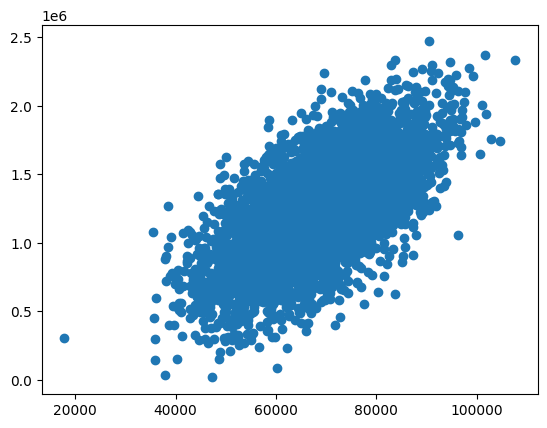

In [ ]:
plt.scatter(df.iloc[:, :1], y)

In [ ]:
data_frame = df[["Avg. Area Income", "Avg. Area House Age", "Avg. Area Number of Rooms", "Area Population"]]
scaler = MinMaxScaler()
df_scaled = scaler.fit_transform(data_frame)

In [ ]:
y = df.Price
X_train, X_test, y_train, y_test = train_test_split(df_scaled, y, test_size=0.2)

In [ ]:
model = LinearRegression()
model.fit(X_train, y_train)

LinearRegression()

In [ ]:
model.score(X_test, y_test)

0.9258631496755102

In [ ]:
df_scaled

array([[0.68682217, 0.44198584, 0.50150158],
       [0.68352073, 0.48853836, 0.46450137],
       [0.48373705, 0.46860901, 0.70135011],
       ...,
       [0.50713527, 0.67002636, 0.20853446],
       [0.55841872, 0.4203891 , 0.51757886],
       [0.53071451, 0.48699729, 0.47267788]])

In [ ]:
df.columns

Index(['Avg. Area Income', 'Avg. Area House Age', 'Avg. Area Number of Rooms',
       'Avg. Area Number of Bedrooms', 'Area Population', 'Price', 'Address'],
      dtype='object')